# New artist discovery
How many artists show up for the first time each month, and how much of each month's listening goes to them.

## Load data
Uses `scrobbles.parquet` from the project folder, or `sample_data/` if it isn't there.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

from viz import BAR_COLOR, SURFACE, INK, MUTED, GRID, BASELINE, add_title, save_figure

DATA_DIR = '.' if os.path.exists('scrobbles.parquet') else 'sample_data'  # falls back to the bundled sample
print(f'data: {DATA_DIR}')

df = pd.read_parquet(f'{DATA_DIR}/scrobbles.parquet')
print(df.shape)

data: .
(33736, 5)


## First month per artist
An artist counts as new in the month of their earliest scrobble. "New" here means new to the scrobble history, so the first month of the history is left out (every artist is new then), along with the current month, which is still in progress.

In [2]:
local = df['played_at'].dt.tz_localize(None)  # drop the timezone, keep local wall-clock time
month = local.dt.to_period('M').rename('month')
plays = df[['artist']].assign(month=month)

first_month = plays.groupby('artist')['month'].min().rename('first_month')  # earliest month each artist was played
plays = plays.join(first_month, on='artist')
plays['is_new'] = plays['month'] == plays['first_month']  # a play in the artist's first month

keep = (plays['month'] > plays['month'].min()) & (plays['month'] < plays['month'].max())
plays = plays[keep]

new_artists = first_month.value_counts().reindex(sorted(plays['month'].unique()), fill_value=0)  # artists first heard each month
new_share = plays.groupby('month')['is_new'].mean() * 100  # percent of each month's plays

discovery = pd.DataFrame({'new_artists': new_artists, 'new_share': new_share})
discovery.index = discovery.index.to_timestamp()
discovery.tail()

,new_artists,new_share
2026-06-01,98,11.877076
2026-07-01,89,7.446809
2026-08-01,37,13.129103
2026-09-01,31,5.555556
2026-10-01,20,4.353083


## Charts
New artists per month on top, and the share of plays that went to artists first heard that month below.

findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.
findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


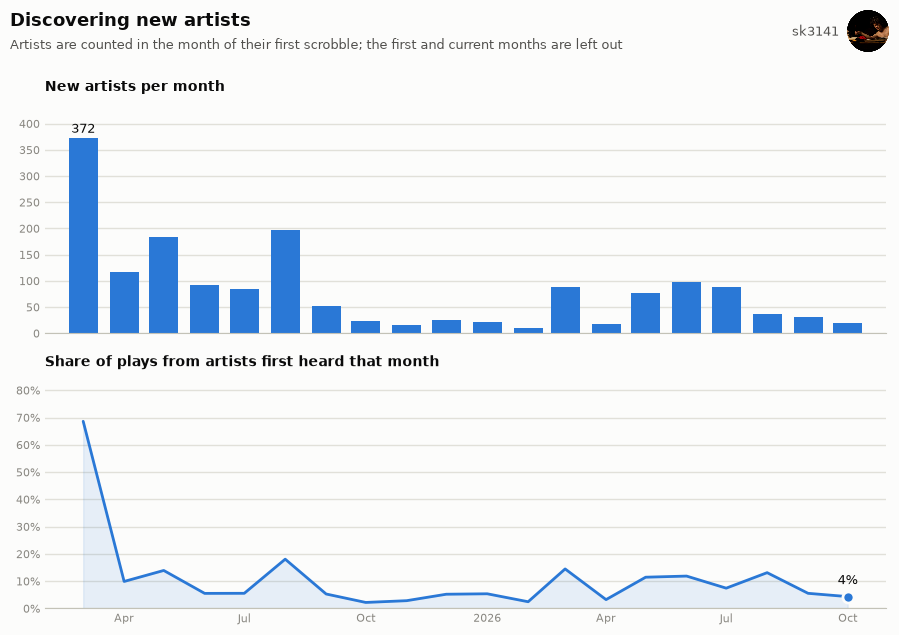

In [3]:
def plot_discovery(discovery, save=False):
    '''New artists per month (bars) and the share of plays they account for (line).'''
    height = 6.4
    fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, height), sharex=True, facecolor=SURFACE)
    months = discovery.index

    top.bar(months, discovery['new_artists'], width=22, color=BAR_COLOR)
    peak = discovery['new_artists'].idxmax()
    top.annotate(f"{discovery['new_artists'].max():.0f}", (peak, discovery['new_artists'].max()),
                 textcoords='offset points', xytext=(0, 4), ha='center', fontsize=9, color=INK)
    top.set_title('New artists per month', loc='left', fontsize=10, fontweight='bold', color=INK)

    share = discovery['new_share']
    bottom.plot(months, share, color=BAR_COLOR, linewidth=2, solid_capstyle='round')
    bottom.fill_between(months, share, color=BAR_COLOR, alpha=0.1)
    bottom.plot(months[-1], share.iloc[-1], 'o', markersize=8, color=BAR_COLOR,
                markeredgecolor=SURFACE, markeredgewidth=2)
    bottom.annotate(f'{share.iloc[-1]:.0f}%', (months[-1], share.iloc[-1]),
                    textcoords='offset points', xytext=(0, 9), ha='center', fontsize=9, color=INK)
    bottom.set_title('Share of plays from artists first heard that month', loc='left',
                     fontsize=10, fontweight='bold', color=INK)
    bottom.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    bottom.set_ylim(0, share.max() * 1.25)

    for ax in (top, bottom):
        ax.set_facecolor(SURFACE)
        ax.margins(x=0.03)
        ax.yaxis.grid(True, color=GRID, linewidth=1)
        ax.set_axisbelow(True)
        for side in ('top', 'right', 'left'):
            ax.spines[side].set_visible(False)
        ax.spines['bottom'].set_color(BASELINE)
        ax.tick_params(length=0, labelsize=8, labelcolor=MUTED)
    top.set_ylim(0, discovery['new_artists'].max() * 1.2)

    locator = mdates.AutoDateLocator(minticks=5, maxticks=9)
    bottom.xaxis.set_major_locator(locator)
    bottom.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    add_title(fig, 'Discovering new artists',
              'Artists are counted in the month of their first scrobble; the first and current months are left out', height)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.65 / height))
    if save:
        save_figure(fig, 'new_artist_discovery')
    plt.show()


plot_discovery(discovery, save=True)